# FBI over MCP

The three tools as a model sees them. [`client.ipynb`](client.ipynb) uses the
Python client directly; this goes through the server, which is what yada and
any agent will do.

**The server must be running, and it must be newer than the tools *and* than
their arguments.** It does not hot-reload. A server started before
`fbi_arrests` existed serves the old tool list and the call fails as "unknown
tool" — uninformative, but a failure. A server started before an *argument*
existed does not fail at all: FastMCP drops an argument it does not recognise
and answers as though it were never passed, so a request for one arrest code
comes back as the total for all of them. Section 6 is the guard that turns the
silent case into the loud one, and it is why this notebook calls through
`utils/mcp.py` rather than opening a client of its own.

Sections 1 to 3 walk the three tools. Sections 4 and 5 are what a response says
about itself, which is most of the interface. Section 6 is the guard, section 7
the arithmetic this notebook does and the rule it does it under, section 8
discovery.

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Anchor on this notebook's own directory rather than on the working directory:
# VS Code can root a notebook at the workspace folder instead of at the file,
# and then a relative "../" resolves somewhere else entirely and the imports
# below fail with ModuleNotFoundError.
_here = Path.cwd()
_FBI = _here if (_here / "utils" / "mcp.py").exists() else _here / "notebooks" / "fbi"
for _path in (str(_FBI), str(_FBI.parents[1])):      # notebooks/fbi, then the meida root
    if _path not in sys.path:
        sys.path.insert(0, _path)

import asyncio
import textwrap
import time
from collections.abc import Iterable
from datetime import datetime
from typing import Any

from matplotlib import pyplot
# Matplotlib accepts a datetime on an axis and converts it with this same
# function; calling it here keeps the type checker's account of the call
# honest, since the stubs type these parameters as floats.
from matplotlib.dates import date2num

from lib import config
from lib.mcp_client import MCPClient, MCPClientConfig
from lib.utils import print_json_vertical
from utils.mcp import (MCP_URL, StaleServerError, call_tool as _call_tool,
                       clearance_rate, list_tools, observations, rolling_12, unfiled)

pyplot.style.use(config.glyfish_style)

#: One tool response. The tools return a typed model and FastMCP serialises it,
#: so what a caller holds is a plain dict -- which is the form the rule in
#: section 7 is written for.
Payload = dict[str, Any]

#: Seconds between requests, and what to do when one is refused anyway. The
#: 1,000-an-hour allowance is shared across everything using the key, and a
#: burst is answered with "503 upstream connect error" -- which is charged to
#: the allowance as well, and which the client behind the tool already retries
#: four times, five, ten and twenty seconds apart. In a run of this length that
#: is sometimes not enough, so a refusal waits a minute and tries again rather
#: than losing the run.
PACE = 5.0
REFUSED_WAIT = 60.0
ATTEMPTS = 4
_last_call = 0.0
_spent = 0              # calls that answered, reported by the last cell
_refused = 0            # refusals, which cost the allowance and bought nothing


async def call_tool(name: str, arguments: dict[str, Any]) -> Payload:
    """utils.mcp.call_tool, paced, and repeated while the gateway refuses it.

    A StaleServerError is re-raised at once: waiting does not restart a server
    that predates the tool or the argument being asked for, and the message it
    carries says what to do instead.
    """
    global _last_call, _spent, _refused
    for attempt in range(ATTEMPTS):
        await asyncio.sleep(max(0.0, PACE - (time.monotonic() - _last_call))
                            if attempt == 0 else REFUSED_WAIT)
        try:
            payload = await _call_tool(name, arguments)
        except StaleServerError:
            raise
        except RuntimeError:
            _refused += 1
            if attempt == ATTEMPTS - 1:
                raise
            continue
        finally:
            _last_call = time.monotonic()
        _spent += 1
        return payload
    raise RuntimeError("unreachable")


def notices(payload: Payload, *, whole: bool = True, width: int = 88,
            brief: int = 210) -> None:
    """Print a response's notices, wrapped, whole or as opening sentences.

    They are paragraphs rather than labels -- the schedule notice in section 4
    runs to two hundred words -- because they are written for a model reading
    one response with no second request to spend on the question. Printing them
    whole is the point in two places here and noise everywhere else.
    """
    for index, notice in enumerate(payload.get("notices", []), 1):
        # A notice that is one sentence long has no ". " to split on and comes
        # back whole, full stop included, so the period is stripped before one
        # is added rather than after.
        opening = notice.split(". ")[0].rstrip(".") + "."
        text = (notice if whole else
                textwrap.shorten(opening, width=brief, placeholder=" …"))
        print(textwrap.fill(text, width=width, initial_indent=f"  {index}. ",
                            subsequent_indent="     "))


def in_order(periods: Iterable[str]) -> list[str]:
    """Periods sorted by date. 'MM-YYYY' does not sort as text."""
    return sorted(periods, key=lambda period: period[3:] + period[:2])


print(f"{MCP_URL}\n")
for name, summary in await list_tools("fbi_"):
    print(f"{name:16} {summary}.")

http://localhost:8096/sse

fbi_offenses     Monthly offences known to law enforcement, or clearances of them, from the FBI Crime Data Explorer (1985 onwards).
fbi_arrests      Monthly ARRESTS from the FBI Crime Data Explorer, for all offences together or for one offence.
fbi_employment   Annual sworn officers or civilian employees at ONE law-enforcement agency, from the FBI Crime Data Explorer (1985 onwards).


## 1. Three tools, one per retrieval route

FRED and CDC each carry six because they have category trees and dataset
vocabularies to walk. The FBI needs none: discovery goes through the catalogue
(section 8), so this source adds one tool per retrieval route and nothing else.
There are three routes, so three tools.

    fbi_offenses(offense, scope, measure, unit, start, end)   monthly, 1985–
    fbi_arrests(scope, unit, start, end, offense)             monthly, 01-2018 verified
    fbi_employment(ori, measure, start, end)                  annual, 1985–

`scope` takes all three geographic grains as one string on both monthly tools:
`national`, a state code, or an agency ORI. `offense` is the only argument on
either that reaches the FBI — it is a segment of the request path rather than a
query parameter — and on the arrest route it is the only way to narrow a
request at all. `measure` and `unit` never leave the server: one payload
already carries offences and clearances as counts and as rates, and the tool
selects from it.

`offense` sits **last** on `fbi_arrests`, after `end`, which reads oddly and is
deliberate: a positional call written before the argument existed —
`(scope, unit, start, end)` — still binds the way it did.

The closed vocabularies are published as JSON Schema enums, built from the
client's own tables rather than restated beside them, so an unknown value is
refused at the tool boundary before it can become a failed request against a
key that locks out every job sharing it. The cell below reads them off the
server rather than off this page, and it is also where section 6 gets the list
of arguments a call is checked against.

In [2]:
# No CDE request here: a tool listing is the server's own, and the same listing
# is what call_tool checks an argument against before spending anything.
async with MCPClient(MCPClientConfig(url=MCP_URL)) as _client:
    schemas: dict[str, dict[str, Any]] = {
        tool.name: (tool.inputSchema or {}).get("properties", {})
        for tool in await _client.list_tools() if tool.name.startswith("fbi_")}

for name, properties in schemas.items():
    print(f"{name}({', '.join(properties)})")
    for argument, schema in properties.items():
        vocabulary = schema.get("enum")
        shown = ", ".join(str(value) for value in (vocabulary or [])[:7])
        print(f"    {argument:9} default {str(schema.get('default', '—')):10} "
              + (f"{len(vocabulary):>2} values: {shown}"
                 + (", …" if len(vocabulary) > 7 else "") if vocabulary else "free text"))

fbi_offenses(offense, scope, measure, unit, start, end)
    offense   default —          10 values: violent-crime, homicide, rape, robbery, aggravated-assault, property-crime, burglary, …
    scope     default national   free text
    measure   default offenses    2 values: offenses, clearances
    unit      default count       2 values: count, rate
    start     default 01-1985    free text
    end       default None       free text
fbi_arrests(scope, unit, start, end, offense)
    scope     default national   free text
    unit      default count       2 values: count, rate
    start     default 01-1985    free text
    end       default None       free text
    offense   default all        48 values: all, 11, 12, 20, 23, 30, 50, …
fbi_employment(ori, measure, start, end)
    ori       default —          free text
    measure   default officers    2 values: officers, civilians
    start     default 1985       free text
    end       default None       free text


## 2. `fbi_offenses` — offences known to the police, and clearances of them

One call, one series, because the catalogue entry that sent you here describes
one series. The payload the API returned held four for this scope and window —
offences and clearances, each as a count and a rate — and `measure` and `unit`
chose among them on the server rather than in the request.

In [3]:
national = await call_tool("fbi_offenses", {
    "offense": "homicide", "scope": "national", "measure": "offenses",
    "start": "01-2015", "end": "12-2024",
})
print_json_vertical({key: value for key, value in national.items()
                     if key not in ("observations", "population",
                                    "participated_population", "coverage", "notices")})
print(f"\n{len(national['observations'])} monthly observations, and three context series:")
for field in ("population", "participated_population", "coverage"):
    context = national[field]
    print(f"  {field:24} {context['label']:16} {context['unit']:20} "
          f"{len(context['observations'])} periods")

{
  "coverage_mean_percent": 94.55,
  "coverage_min_percent": 74.12,
  "coverage_min_period": "02-2021",
  "frequency": "Monthly",
  "geography": "United States",
  "last_refresh_date": "09/15/2026",
  "max_data_date": "09/2026",
  "measure": "offenses",
  "observation_end": "12-2024",
  "observation_start": "01-2015",
  "offense": "homicide",
  "scope": "national",
  "unit": "count"
}

120 monthly observations, and three context series:
  population               United States    people               120 periods
  participated_population  United States    participated people  120 periods
  coverage                 United States    percent              120 periods


What rides along is context rather than more data: the two population
denominators, the reporting coverage, and the vintage. All three arrive in the
same payload, so returning the series without them would only make a second
call necessary to learn whether the first is usable. Each carries its own
`label`, which is how a state's figure standing in for an agency's becomes
visible — see the third grain below.

`population` is residents and `participated_population` is the people living
where agencies reported. They are not interchangeable and the rate divides by
the second, which is section 5.

## Coverage is the reason to trust or distrust a year

In [4]:
print(f"coverage: mean {national['coverage_mean_percent']}%, "
      f"minimum {national['coverage_min_percent']}% in {national['coverage_min_period']}")
notices(national)

coverage: mean 94.55%, minimum 74.12% in 02-2021
  1. This series spans 2021, when the FBI retired the Summary Reporting System for
     NIBRS. Two things changed at once: agencies that had not converted stopped
     reporting (the coverage dip), and NIBRS counts every offence in an incident where
     SRS counted only the most serious one. Treat the series as spliced, not continuous.
  2. Coverage bottoms out at 74.12% in 02-2021: that month's figure counts what was
     reported, not what happened.


## The three grains

The same offence at the nation, a state and a city department. Only the `scope`
string changes, and the national response is the one already in hand.

In [5]:
scopes = {"national": "United States", "DC": "District of Columbia",
          "DCMPD0000": "Washington PD"}
series: dict[str, Payload] = {"national": national}
for scope in scopes:
    if scope not in series:
        series[scope] = await call_tool("fbi_offenses", {
            "offense": "homicide", "scope": scope, "measure": "offenses",
            "start": "01-2015", "end": "12-2024",
        })

for scope, label in scopes.items():
    payload = series[scope]
    points = observations(payload)
    total_2024 = sum(value for period, value in points.items() if period.endswith("2024"))
    coverage_label = payload["coverage"]["label"]
    print(f"  {label:22} {payload['geography'][:34]:34} "
          f"2024 homicides {total_2024:>7,.0f}   coverage min "
          f"{payload['coverage_min_percent']:>6.2f}%  ({coverage_label}"
          f"{'' if coverage_label == payload['geography'] else ' ← not this department'})")

  United States          United States                      2024 homicides  17,261   coverage min  74.12%  (United States)
  District of Columbia   District of Columbia               2024 homicides     181   coverage min 100.00%  (District of Columbia)
  Washington PD          Washington Police Department       2024 homicides     181   coverage min 100.00%  (District of Columbia ← not this department)


The state and the department report the same 2024 total here. They are not the
same series and nothing on either response says they coincide, so a caller
holding one of them cannot read it as the other. Washington's department reports
fully throughout while the national series drops to about 74% in 2021, which is
why a city series crosses that year more cleanly than the national one — though
the counting-rule change NIBRS brought applies to both.

The department's coverage figure is its **state's**. An agency publishes none
of its own, and the notice says so rather than leaving the substitution to be
noticed. That is the single most important thing about the coverage series: it
cannot show one agency going dark, which is what sections 4 and 7 are about.

## 3. `fbi_arrests` — arrests, for all offences or for one

The second monthly route, and the only one whose request narrows by offence.
`scope`, `unit`, `start` and `end` behave as they do on `fbi_offenses`;
`offense` is a UCR **arrest code**, not an `fbi_offenses` slug, and the slugs
do not transfer — `violent-crime` is refused, because there is no violent-crime
code. The vocabulary printed in section 1 is 48 values: `all` and 47 codes.
`all` is the default, so a call that passes nothing gets every offence
together.

An arrest here is one person arrested, cited or summoned on one occasion, filed
under a single code. What the response has to say about which offence it
counts is worth reading twice, because the payload underneath it says nothing
at all: every code comes back from the CDE labelled "United States Arrests",
murder and disorderly conduct alike, so `offense` and `offense_name` are the
only record of what the numbers are.

In [6]:
arrests: dict[str, Payload] = {}
for code in ("all", "11"):
    arrests[code] = await call_tool("fbi_arrests", {
        "scope": "national", "offense": code, "unit": "count",
        "start": "01-2018", "end": "12-2024",
    })

print_json_vertical({key: value for key, value in arrests["11"].items()
                     if key not in ("observations", "population",
                                    "participated_population", "coverage", "notices")})

print()
for code, payload in arrests.items():
    points = observations(payload)
    for year in ("2018", "2023", "2024"):
        total = sum(value for period, value in points.items() if period.endswith(year))
        print(f"  offense={code:4} {payload['offense_name']:34} {year} "
              f"{total:>12,.0f} arrests")

{
  "coverage_mean_percent": 93.39,
  "coverage_min_percent": 74.12,
  "coverage_min_period": "02-2021",
  "frequency": "Monthly",
  "geography": "United States",
  "last_refresh_date": "09/15/2026",
  "max_data_date": "09/2026",
  "measure": "arrests",
  "observation_end": "12-2024",
  "observation_start": "01-2018",
  "offense": "11",
  "offense_name": "Murder and Nonnegligent Homicide",
  "scope": "national",
  "unit": "count"
}

  offense=all  All Crimes                         2018   10,565,759 arrests
  offense=all  All Crimes                         2023    7,184,021 arrests
  offense=all  All Crimes                         2024    7,111,076 arrests
  offense=11   Murder and Nonnegligent Homicide   2018       10,257 arrests
  offense=11   Murder and Nonnegligent Homicide   2023       11,451 arrests
  offense=11   Murder and Nonnegligent Homicide   2024       10,312 arrests


Two things that a caller holding only those numbers would get wrong, and the
response says both.

The first is the one this pairing invites: **an arrest is not a clearance**, so
the gap between murder arrests and homicide clearances is not the clearances
made by exceptional means. One arrest can clear several offences and several
arrests can clear one; most arrests are for offences `fbi_offenses` has no
series for at all. That sentence is on every arrest response unconditionally,
because it is always true and because two routes sitting side by side make the
difference easy to miss.

The second is that some of the FBI's own code names mislead, and the response
names the ones that do rather than leaving a caller to discover that code 50,
"Assault - Not Specified", is aggravated assault.

In [7]:
notices(arrests["11"])

  1. Arrests for Murder and Nonnegligent Homicide only (UCR arrest code 11). Each arrest
     is filed under one code; nationally in 2023, the one window checked, the codes add
     up to 'all' bar 905 arrests filed under 'Suspicion', which has no code. An arrest
     is NOT a clearance: an arrest counts one person arrested, cited or summoned on one
     occasion, a clearance counts one offence closed, and one arrest can clear several
     offences while several arrests can clear one. The two routes also carry their own
     coverage. So this cannot be differenced against fbi_offenses' clearances — not in
     total and not for the same offence — and the pair does not show how many clearances
     were made by exceptional means.
  2. This series spans 2021, when the FBI retired the Summary Reporting System for
     NIBRS. Two things changed at once: agencies that had not converted stopped
     reporting (the coverage dip), and NIBRS counts every offence in an incident where
     SRS co

## 4. The notices are how a response says what it cannot show

Everything above this point is a number with a label on it. The rest of the
interface is prose, and it is not decoration: the CDE writes "nobody filed" as
a number, and which number is arbitrary — most routes and scopes send `0`, some
send `null`, and a run can mix the two. Nothing in the payload distinguishes
either from a month in which nothing happened. A test on `value is not None`
therefore counts a missing return as an observation, and a sum across one
invents data.

So the tools read the filings before returning them. A run of blanks whose
length times the level of the filings around it is large enough to be
improbable is a missing return, and those months come back as **`null`**, with
`observation_start` and `observation_end` naming the filings rather than the
window that was asked for, and a notice naming the spans. Nulling rather than
flagging is the whole point: a caller who sums without reading the prose gets a
plausible, wrong, silent answer from a `0` and a loud one from a `null`.

Washington's homicide series over its full history carries most of the notice
kinds at once, which is why it is the example.

In [8]:
washington = await call_tool("fbi_offenses", {
    "offense": "homicide", "scope": "DCMPD0000", "measure": "offenses",
    "start": "01-1985", "end": "12-2024",
})
spelt = [observation["value"] for observation in washington["observations"]]
print(f"window 01-1985..12-2024, {len(spelt)} months; filings "
      f"{washington['observation_start']}..{washington['observation_end']}; "
      f"{sum(1 for value in spelt if value is None)} returned null, "
      f"{sum(1 for value in spelt if value == 0)} returned as a filed 0\n")
notices(washington, whole=False)

window 01-1985..12-2024, 480 months; filings 01-1985..12-2024; 7 returned null, 29 returned as a filed 0

  1. This series spans 2021, when the FBI retired the Summary Reporting System for
     NIBRS.
  2. Coverage or population is labelled District of Columbia rather than Washington
     Police Department: the payload carries none for the requested geography itself, so
     the context is the wider one it does carry.
  3. 7 of the 480 months in this window record no filing: 01-2021..07-2021.
  4. 4 quarterly returns in this window: a run of 2 blank months closed by a filing
     carrying the whole quarter (01-1993..02-1993 closed by 03-1993 (113 offences
     against 105 for 3 months), 04-1993..05-1993 closed …
  5. 2 semiannual returns in this window: a run of 5 blank months closed by a filing
     carrying the whole half-year (01-1996..05-1996 closed by 06-1996 (198 offences
     against 198 for 6 months), 07-1996..11-1996 …
  6. 1 annual return in this window: a run of 11 blank mon

Two of those notices say something a caller has to act on differently.

**The months nobody filed are null.** Seven of 2021, while the department
converted to NIBRS. Summing the year as it arrives gives what the department
filed in five months, not what happened in twelve.

**The periodic returns are handed back as the CDE sent them.** An agency filing
quarterly or annually sends the blanks *and* a month carrying the whole period,
and the payload says nothing about the pair. Nulling those blanks and keeping
the lump as one month's value would leave a monthly mean three or twelve times
too high, where before any rule a sum over whole periods was right. So the
schedule is recognised — a run of two, five or eleven blanks closed by a filing
that carries between half and twice the period's expected filings — and the
blanks keep the `0` they arrived as. A caller summing whole years is right
without reading anything; a caller reading one month inside a span is wrong,
and that is what the notice is for.

The cell below is the arithmetic those two notices are about, on four years of
one series: three under a schedule, one an ordinary monthly year, one a gap.

In [9]:
def year_of(payload: Payload, year: str) -> list[float | None]:
    """The twelve months of one year, in order, as the response spells them."""
    month = {observation["period"][:2]: observation["value"]
             for observation in payload["observations"]
             if observation["period"].endswith(year)}
    return [month.get(f"{index:02d}") for index in range(1, 13)]


print(f"{'year':6} {'what the response spells':40} {'total':>7} {'/12':>7} "
      f"{'/filed':>7}  reading")
for year, reading in (("1993", "quarterly — four filings of a quarter"),
                      ("1996", "semiannual — two filings of a half-year"),
                      ("1997", "annual — one filing of the year"),
                      ("1998", "monthly — twelve filings"),
                      ("2021", "a gap — seven months nobody filed")):
    months = year_of(washington, year)
    filed = [value for value in months if value]
    blank = sum(1 for value in months if value == 0)
    nulled = sum(1 for value in months if value is None)
    total = sum(filed)
    plural = "" if len(filed) == 1 else "s"
    spelt = (f"{len(filed)} filing{plural}, {blank} zeros" if blank else
             f"{len(filed)} filing{plural}, {nulled} nulls" if nulled else
             f"{len(filed)} filing{plural}")
    print(f"{year:6} {spelt:40} {total:>7,.0f} {total / 12:>7.1f} "
          f"{total / len(filed):>7.1f}  {reading}")

print("\n'/12' is the right monthly mean for the three scheduled years and the wrong "
      "one for 2021,\nwhere five months carry the total and the other seven are null "
      "rather than 0:\n2021 sums to what was filed, against 1998's twelve filings and "
      "1997's one.")

year   what the response spells                   total     /12  /filed  reading
1993   4 filings, 8 zeros                           454    37.8   113.5  quarterly — four filings of a quarter
1996   2 filings, 10 zeros                          397    33.1   198.5  semiannual — two filings of a half-year
1997   1 filing, 11 zeros                           301    25.1   301.0  annual — one filing of the year
1998   12 filings                                   260    21.7    21.7  monthly — twelve filings
2021   5 filings, 7 nulls                           116     9.7    23.2  a gap — seven months nobody filed

'/12' is the right monthly mean for the three scheduled years and the wrong one for 2021,
where five months carry the total and the other seven are null rather than 0:
2021 sums to what was filed, against 1998's twelve filings and 1997's one.


## A trailing blank run is judged by route, not by rule

The run at the *end* of a window is the one case where the answer depends on
which series was asked for rather than only on the numbers, and it does so
because the evidence differs rather than because the rule does. On the offence
route the vintage decides: blanks at or past `max_data_date` are the CDE
padding a window past the data it holds, while a run ending before it is judged
by its mass like any interior run, since the data carries on past the window.
An arrest run is nulled at any length at agency scope, because an agency's
participated population carries on after the agency stops filing and nothing
else in the payload can tell a department that went dark from a quiet quarter.

Three responses below, each a different answer to the same shape.

In [10]:
washington_arrests = await call_tool("fbi_arrests", {
    "scope": "DCMPD0000", "offense": "all", "unit": "count",
    "start": "01-1990", "end": "12-2024"})
san_francisco = await call_tool("fbi_arrests", {
    "scope": "CA0380100", "offense": "11", "unit": "count",
    "start": "01-2018", "end": "12-2024"})
numbers_racket = await call_tool("fbi_arrests", {
    "scope": "national", "offense": "172", "unit": "count",
    "start": "01-2023", "end": "12-2024"})

def spelling(payload: Payload) -> tuple[str, str, int, int]:
    """The window asked for, the span of filings, and how the blanks are spelt."""
    values = [observation["value"] for observation in payload["observations"]]
    periods = [observation["period"] for observation in payload["observations"]]
    return (f"{periods[0]}..{periods[-1]}",
            f"{payload['observation_start']}..{payload['observation_end']}",
            sum(1 for value in values if value is None),
            sum(1 for value in values if value == 0))


print(f"  {'request':34} {'asked for':18} {'filings':18} {'null':>5} {'0':>4} "
      f"{'coverage mean/min':>18}")
for label, payload in (("fbi_arrests(DCMPD0000, all)", washington_arrests),
                       ("fbi_arrests(CA0380100, 11)", san_francisco),
                       ("fbi_arrests(national, 172)", numbers_racket),
                       ("fbi_offenses(DCMPD0000, homicide)", washington)):
    window, filings, nulls, zeros = spelling(payload)
    print(f"  {label:34} {window:18} {filings:18} {nulls:>5} {zeros:>4} "
          f"{payload['coverage_mean_percent']:>8.2f}%"
          f"{payload['coverage_min_percent']:>8.2f}%")

print("\nSan Francisco, murder arrests, the last fourteen months asked for:")
print("  " + ", ".join(
    f"{observation['period']} "
    + ("null" if observation["value"] is None else f"{observation['value']:.0f}")
    for observation in san_francisco["observations"][-14:]))
print()
notices(san_francisco, whole=False)
print("\nThe national single code, where a blank means no arrest rather than no return:")
notices(numbers_racket, whole=False)
print("  the three filings behind those 24 months: "
      + ", ".join(f"{period} {value:.0f}"
                  for period, value in observations(numbers_racket).items() if value))

  request                            asked for          filings             null    0  coverage mean/min
  fbi_arrests(DCMPD0000, all)        01-1990..12-2024   01-1990..12-2024     307   44   100.00%  100.00%
  fbi_arrests(CA0380100, 11)         01-2018..12-2024   01-2018..12-2023      24    5    88.89%   20.56%
  fbi_arrests(national, 172)         01-2023..12-2024   01-2023..12-2024       0   21    96.18%   95.00%
  fbi_offenses(DCMPD0000, homicide)  01-1985..12-2024   01-1985..12-2024       7   29   100.00%  100.00%

San Francisco, murder arrests, the last fourteen months asked for:
  11-2023 8, 12-2023 4, 01-2024 null, 02-2024 null, 03-2024 null, 04-2024 null, 05-2024 null, 06-2024 null, 07-2024 null, 08-2024 null, 09-2024 null, 10-2024 null, 11-2024 null, 12-2024 null

  1. Arrests for Murder and Nonnegligent Homicide only (UCR arrest code 11).
  2. This series spans 2021, when the FBI retired the Summary Reporting System for
     NIBRS.
  3. Coverage bottoms out at 20.56% in 02-2

San Francisco's 2024 is nulled whole — twelve months, at an agency, on the
arrest route — and `observation_end` falls a year short of the end that was
asked for. The notice states what the payload cannot settle: whether the
department stopped filing or the window merely ended on a quiet stretch. Its
2021 is null for a different reason, and gets its own sentence: no participated
population at all that year, so nobody reported and a zero would be a claim.

Nationally for one code the CDE spells a month with **no arrest** as `null`
rather than `0`, which is the opposite convention to everywhere else, and
reading it as a missing return would cost this series its span and invent a
"data stops" notice two years before the data does. So a null is read as `0`
where the payload says the scope reported — the month is not past
`max_data_date` and the scope's own participated population is above zero —
which is how the FBI's own annual totals count those months. Twenty-one of
twenty-four months here, and the three filings left are the whole of what that
code recorded in those two years.

Washington's arrests are the case the coverage series is blind to: 307
consecutive months with no filing, at a mean and a minimum coverage of 100%,
because an agency publishes no coverage of its own and the percentage carried is
the District's. Before the rule existed the same series advertised itself as
complete.

## 5. A rate is per participated population, and is nulled where its count is

Both monthly routes publish a rate, and it divides by the people living where
agencies reported rather than by residents. That series is returned, under its
own unit — `participated people` against `population`'s `people`, so the two,
which share their labels, cannot be picked up for each other — which makes a
rate recomputable rather than something to be trusted.

The gap is not small, and it is widest exactly where the series is least
trustworthy: the months when fewest agencies reported are the months when the
two denominators differ most.

In [11]:
arrest_rate = await call_tool("fbi_arrests", {
    "scope": "national", "offense": "all", "unit": "rate",
    "start": "01-2018", "end": "12-2024"})


def block(payload: Payload, field: str) -> dict[str, float]:
    """One context series as ``{period: value}``."""
    return {observation["period"]: observation["value"]
            for observation in (payload.get(field) or {}).get("observations", [])
            if observation["value"] is not None}


arrest_counts = observations(arrests["all"])
published = observations(arrest_rate)
participated = block(arrests["all"], "participated_population")
residents = block(arrests["all"], "population")
shared = [period for period in in_order(published)
          if period in arrest_counts and period in participated and period in residents]

print(f"{'month':8} {'arrests':>10} {'participated':>14} {'residents':>14} "
      f"{'published':>10} {'÷participated':>14} {'÷residents':>11}")
for period in ("01-2018", "06-2021", "01-2023", "12-2024"):
    print(f"{period:8} {arrest_counts[period]:>10,.0f} {participated[period]:>14,.0f} "
          f"{residents[period]:>14,.0f} {published[period]:>10.2f} "
          f"{1e5 * arrest_counts[period] / participated[period]:>14.2f} "
          f"{1e5 * arrest_counts[period] / residents[period]:>11.2f}")

worst = {
    "participated population": max(
        abs(1e5 * arrest_counts[period] / participated[period] - published[period])
        for period in shared),
    "residents": max(
        abs(1e5 * arrest_counts[period] / residents[period] - published[period])
        for period in shared),
}
print(f"\nover all {len(shared)} months, the widest gap against the published rate: "
      f"{worst['participated population']:.4f} per 100,000 dividing by participated "
      f"population, {worst['residents']:.2f} dividing by residents")

month       arrests   participated      residents  published  ÷participated  ÷residents
01-2018     866,322    323,310,779    330,362,587     267.95         267.95      262.23
06-2021     446,340    258,303,259    335,395,039     172.80         172.80      133.08
01-2023     580,792    323,289,818    338,357,687     179.65         179.65      171.65
12-2024     547,408    331,158,128    343,551,384     165.30         165.30      159.34

over all 84 months, the widest gap against the published rate: 0.0049 per 100,000 dividing by participated population, 44.83 dividing by residents


Dividing by residents is wrong by about 5 per 100,000 in a month at full
coverage and by 40 in June 2021, which is the direction that matters: the error
is largest in the year the series is already spliced.

Two traps in that, and neither is visible from one month. At small counts
`population` still lands on the published figure, because two decimals hide the
gap — so a match is not evidence. And at agency scope the two populations are
the same number in every month the agency has one, so an agency payload cannot
tell them apart at all.

Whether a month records a filing is a fact about the **return**, not about the
unit it is read in, so the rule runs on the count and what it nulls is nulled
in the rate as well. It has to work that way: the floor separating a missing
return from a quiet month is measured in filings, so a rate judged in its own
units passes 0.3 per 100,000 as a quiet stretch where the count behind it is a
gap, and one request would answer two ways.

In [12]:
washington_rate = await call_tool("fbi_offenses", {
    "offense": "homicide", "scope": "DCMPD0000", "measure": "offenses", "unit": "rate",
    "start": "01-1985", "end": "12-2024"})

nulled = {unit: {observation["period"] for observation in payload["observations"]
                 if observation["value"] is None}
          for unit, payload in (("count", washington), ("rate", washington_rate))}
print(f"count nulls {len(nulled['count'])}, rate nulls {len(nulled['rate'])}, "
      f"the same months: {nulled['count'] == nulled['rate']}")
print(f"  {', '.join(in_order(nulled['rate']))}")
print("\nthe sentence the rate series carries and the count series does not:")
judged = next(notice for notice in washington_rate["notices"]
              if "This is the rate series" in notice)
print(textwrap.fill(judged, width=88, initial_indent="  ", subsequent_indent="  "))

count nulls 7, rate nulls 7, the same months: True
  01-2021, 02-2021, 03-2021, 04-2021, 05-2021, 06-2021, 07-2021

the sentence the rate series carries and the count series does not:
  This is the rate series, and whether a month records a filing is decided on the COUNT
  of offences for the same geography, measure and month, then applied here: a month is
  filed or not, which is a fact about the return rather than about the unit it is read
  in. The floor that separates a missing return from a quiet month is in offences (25 of
  them), so judged in its own units a rate of 0.3 per 100,000 passes as a quiet stretch
  where the count behind it is a missing return, and one request would answer two ways.
  The months named above are named from the counts; the count and the rate come back
  null in exactly the same months.


## 6. The guard: an argument the server does not advertise

FastMCP drops an argument it does not recognise, without an error. A server
started before `offense` existed therefore answers `fbi_arrests(offense="11")`
with the all-offence total — the two annual figures in section 3 are the two
answers, several hundred times apart, with nothing in the response to say which
question was answered. The tool-name case is loud and this one is silent,
which makes it the worse of the two.

So `utils/mcp.py`'s `call_tool` checks every argument against the schema the
server advertises — the listing section 1 read — and raises before the request
is made. This notebook is where the guard belongs, because this notebook is the
one about the interface; the check costs a listing and no CDE request, and the
thing it prevents costs an hour of wondering why a murder series reads in the
millions.

A misspelt argument and an argument the server predates are indistinguishable
from the client's side, which is why one demonstration covers both.

In [13]:
# No request is spent: the guard raises before the call. "offence" is the
# British spelling, and from the client's side a typo and a server that
# predates the argument look identical -- the name is not in the schema.
try:
    await call_tool("fbi_arrests", {"scope": "national", "offence": "11"})
except StaleServerError as error:
    print(textwrap.fill(str(error), width=88, subsequent_indent="  "))

print(f"\nadvertised: {sorted(schemas['fbi_arrests'])}")
try:
    await call_tool("fbi_offenses", {"offense": "homicide", "ori": "DCMPD0000"})
except StaleServerError as error:
    print("\n" + textwrap.fill(str(error), width=88, subsequent_indent="  "))

http://localhost:8096/sse serves 'fbi_arrests' without the argument(s) ['offence']; it
  accepts ['end', 'offense', 'scope', 'start', 'unit']. The server would drop them
  silently and answer as if they were never passed. It does not hot-reload: restart it
  (and the VS Code debug session running it) to pick up the current
  mcp_server/server.py.

advertised: ['end', 'offense', 'scope', 'start', 'unit']



http://localhost:8096/sse serves 'fbi_offenses' without the argument(s) ['ori']; it
  accepts ['end', 'measure', 'offense', 'scope', 'start', 'unit']. The server would drop
  them silently and answer as if they were never passed. It does not hot-reload: restart
  it (and the VS Code debug session running it) to pick up the current
  mcp_server/server.py.


## 7. The rule this notebook reads blanks with, and why it is the simpler one

The tool has already done this job, better, on the way out. What follows is the
same job done by a caller who has only the numbers — which is worth doing once,
because it is the arithmetic every consumer of these responses has to get right
and because it says what the tool's nulls are worth.

`utils/mcp.py`'s `unfiled()` is the **first** version of the filing rule: the
run test alone, weighed against one median for the whole series, over
`{period: value}` dictionaries. It stays here for three reasons. It reads the
shape a model holds, which is a dict and not an array. One test is all this
notebook needs, because the point is that the problem exists and not where its
boundary lies. And it can be stated in a paragraph.

For analysis it is superseded by `utils/filing.py`, which `walkthrough.ipynb`,
`enforcement.ipynb` and `withdrawal.ipynb` share, and by three things
precisely: it adds a part-filing test — `filing.py`'s own docstring records New
York's aggravated assault for 2021 arriving as 1, 2, 4, 1, 6, 3, 4, 0, 3, 4, 2,
4 against a normal month of about 2,900, which no test on zeros catches — and a
catch-up test; it weighs a run against the *local* level rather than one median
for the whole series; and it has a notion of a month unreadable for a reason
other than being blank. Nothing in
`filing.py` reads a dictionary and nothing here reads an array, neither calls
the other, and this notebook deliberately does not import it.

One wrinkle first, and it is the tool's rule meeting the notebook's.
`observations()` keeps only the months carrying a value, which is the right
reading for a sum and the wrong one for a positional window: with seven months
gone from the dict, twelve consecutive slots span nineteen calendar months. So
the rule is given every month, with a nulled one spelled back to the `0` the
CDE sent — which is the form `unfiled()` was written for.

In [14]:
def as_filed(payload: Payload) -> dict[str, float]:
    """``{period: value}`` for every month, a null back as the 0 the CDE sent.

    unfiled() has to see the blanks to find a run in them, and it counts
    positions rather than dates. observations() drops them, which is right for
    a sum and leaves this rule looking at a nineteen-month window.
    """
    return {observation["period"]:
            0.0 if observation["value"] is None else float(observation["value"])
            for observation in payload["observations"]}


recent = series["DCMPD0000"]
nulls = sum(1 for observation in recent["observations"] if observation["value"] is None)
print(f"the response nulls {nulls} of its {len(recent['observations'])} months; "
      f"observations() returns {len(observations(recent))} points, "
      f"as_filed() {len(as_filed(recent))}")
print(f"unfiled() re-derives: {', '.join(in_order(unfiled(as_filed(recent))))}")
print("  — the same seven months the notice named, from the numbers alone")

# The same rule over the full history, where the tool's answer and this one part
# company: one test cannot tell a quarterly filer from a department that stopped.
taken = unfiled(as_filed(washington))
by_year: dict[str, int] = {}
for period in taken:
    by_year[period[3:]] = by_year.get(period[3:], 0) + 1
tool_nulls = sum(1 for observation in washington["observations"]
                 if observation["value"] is None)
print(f"\nover 01-1985..12-2024 the tool nulls {tool_nulls} months and unfiled() takes "
      f"{len(taken)}: "
      + ", ".join(f"{year} × {count}" for year, count in sorted(by_year.items())))
print(f"  the {len(taken) - tool_nulls} extra are the three schedules of section 4, "
      f"which this rule has no test for:\n  it treats them as gaps and voids the windows "
      f"they sit in. Conservative rather than wrong,\n  and a reason to read the notices "
      f"rather than re-derive them.")

the response nulls 7 of its 120 months; observations() returns 113 points, as_filed() 120
unfiled() re-derives: 01-2021, 02-2021, 03-2021, 04-2021, 05-2021, 06-2021, 07-2021
  — the same seven months the notice named, from the numbers alone

over 01-1985..12-2024 the tool nulls 7 months and unfiled() takes 36: 1993 × 8, 1996 × 10, 1997 × 11, 2021 × 7
  the 29 extra are the three schedules of section 4, which this rule has no test for:
  it treats them as gaps and voids the windows they sit in. Conservative rather than wrong,
  and a reason to read the notices rather than re-derive them.


## The clearance rate, on a rolling year

Clearances divided by offences is the standard measure of enforcement
intensity, and both come from the one tool. On a rolling year, because a single
month's ratio is meaningless: a clearance is recorded when it happens, not when
the offence it closes was committed, so one month can exceed 100%.
`rolling_12()` leaves out any window containing a month nobody filed rather
than summing five filed months into a year.

In [15]:
clearances = await call_tool("fbi_offenses", {
    "offense": "homicide", "scope": "DCMPD0000", "measure": "clearances",
    "start": "01-2015", "end": "12-2024"})
offences = series["DCMPD0000"]

missing = unfiled(as_filed(offences)) | unfiled(as_filed(clearances))
print(f"unfiled months, either measure: {', '.join(in_order(missing)) or 'none'}")

homicides = rolling_12(as_filed(offences))
cleared = rolling_12(as_filed(clearances))
rate = clearance_rate(homicides, cleared)
print(f"{len(homicides)} of {len(as_filed(offences)) - 11} twelve-month windows are clean; "
      f"the {len(as_filed(offences)) - 11 - len(homicides)} dropped are the windows "
      f"touching 2021")
for period in ("12-2016", "12-2019", "12-2020", "12-2021", "12-2022", "12-2024"):
    reading = (f"{rate[period]:5.1f}%  on {homicides[period]:>5,.0f} homicides"
               if period in rate else "    —  (a window containing an unfiled month)")
    print(f"  year to {period}  clearance rate {reading}")

unfiled months, either measure: 01-2021, 02-2021, 03-2021, 04-2021, 05-2021, 06-2021, 07-2021
91 of 109 twelve-month windows are clean; the 18 dropped are the windows touching 2021
  year to 12-2016  clearance rate  68.6%  on   137 homicides
  year to 12-2019  clearance rate  68.1%  on   166 homicides
  year to 12-2020  clearance rate  68.7%  on   198 homicides
  year to 12-2021  clearance rate     —  (a window containing an unfiled month)
  year to 12-2022  clearance rate  43.5%  on   207 homicides
  year to 12-2024  clearance rate  45.3%  on   181 homicides


## Capacity: officers at the same department

`fbi_employment` is agency-only — the national and state endpoints answer 200
with the full response shape and nothing in it — so a staffing panel is built
department by department, pairing each ORI with `fbi_offenses` at the same one.
Counts only: the API's own per-1,000 rates divide by a participated population
that is sometimes zero.

In [16]:
officers = await call_tool("fbi_employment", {"ori": "DCMPD0000", "measure": "officers"})
counts = observations(officers)
print(f"{officers['measure']}, {officers['frequency'].lower()}, "
      f"{officers['observation_start']}..{officers['observation_end']}, "
      f"{len(counts)} years with a return")
for year in ("1985", "1990", "2000", "2010", "2019", "2024", "2025"):
    if year in counts:
        print(f"  {year}  {counts[year]:>6,.0f} sworn officers")
print(f"\n{len(officers['notices'])} notices; {len(counts)} of the "
      f"{len(officers['observations'])} years asked for carry a return.")
print("Filing is voluntary, so years go missing; where one does the notice names it, "
      "including\nthe years the API spells as 0 rather than as an absence, which come "
      "back null because a\nsummed 0 reads as a department of nobody.")
notices(officers)

officers, annual, 1985..2025, 41 years with a return
  1985   3,837 sworn officers
  1990   4,740 sworn officers
  2000   3,628 sworn officers
  2010   3,945 sworn officers
  2019   3,809 sworn officers
  2024   3,276 sworn officers
  2025   2,994 sworn officers

0 notices; 41 of the 41 years asked for carry a return.
Filing is voluntary, so years go missing; where one does the notice names it, including
the years the API spells as 0 rather than as an absence, which come back null because a
summed 0 reads as a department of nobody.


## One department, both halves

Offences, clearance rate and staffing for the same city — the pairing the
enforcement question needs, from two of the three tools and one API.

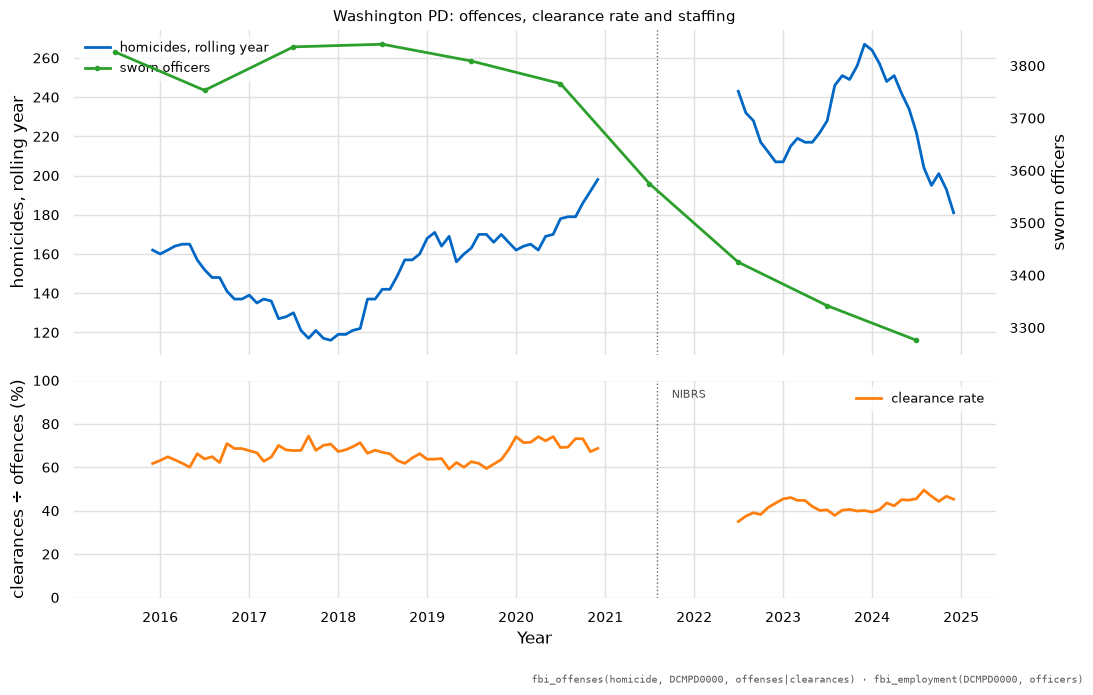

In [17]:
def as_date(period: str) -> datetime:
    """'MM-YYYY' as the first of that month."""
    month, year = period.split("-")
    return datetime(int(year), int(month), 1)


#: Every window the series could carry, in date order -- not only the ones it
#: does. A window dropped for holding an unfiled month has to be drawn as a
#: gap: plotting the windows that exist and letting matplotlib join them puts a
#: straight line across 2021, which is the invented data the rule refuses to
#: return, drawn back in by the plot.
window_months = in_order(as_filed(offences))[11:]


def gapped(points: dict[str, float]) -> list[float]:
    """A rolling series on every candidate window, NaN where it has none."""
    return [points.get(period, float("nan")) for period in window_months]


dates = [as_date(period) for period in window_months]

# Two panels rather than two lines on one axis: homicide counts run in the
# hundreds and a clearance rate runs 0-100, so sharing an axis flattens the
# rate into a line along the bottom and hides the thing worth seeing.
figure, (upper, lower) = pyplot.subplots(2, 1, figsize=(11, 7), sharex=True,
                                         gridspec_kw={"height_ratios": [3, 2]})

staff = upper.twinx()
staff.grid(False)
upper.plot(dates, gapped(homicides), lw=2, label="homicides, rolling year")
staff_years = sorted(int(year) for year in counts if 2015 <= int(year) <= 2024)
staff.plot([datetime(year, 7, 1) for year in staff_years],   # a headcount sits at mid-year
           [counts[str(year)] for year in staff_years], lw=2, color="tab:green",
           marker="o", markersize=3, label="sworn officers")
upper.set_ylabel("homicides, rolling year")
staff.set_ylabel("sworn officers")
lines = upper.get_lines() + staff.get_lines()
upper.legend(lines, [str(line.get_label()) for line in lines], loc="upper left", fontsize=9)
upper.set_title("Washington PD: offences, clearance rate and staffing", fontsize=11)

lower.plot(dates, gapped(rate), lw=2, color="tab:orange", label="clearance rate")
lower.set_ylabel("clearances ÷ offences (%)")
lower.set_xlabel("Year")
lower.set_ylim(0, 100)
lower.legend(loc="upper right", fontsize=9)

# The break in both lines is the eighteen windows that hold one of the seven
# months of 2021 the response returned as null.
for axis in (upper, lower):
    axis.axvline(date2num(datetime(2021, 8, 1)), color="black", lw=1, ls=":", alpha=0.6)
lower.text(date2num(datetime(2021, 10, 1)), 92, "NIBRS", fontsize=8, alpha=0.7)

figure.tight_layout()
figure.subplots_adjust(bottom=0.13)
figure.text(0.995, 0.005,
            "fbi_offenses(homicide, DCMPD0000, offenses|clearances) · "
            "fbi_employment(DCMPD0000, officers)",
            ha="right", va="bottom", fontsize=7, family="monospace", alpha=0.65)
pyplot.show()

The dotted line marks Washington's own conversion, August 2021, at the right
edge of the seven months it filed nothing. Both lines change there, and neither change
is a change in crime: the offence line is spliced — SRS counted only the most
serious offence in an incident and NIBRS counts every one — and both lines break for the
eighteen rolling windows that hold one of the seven unfiled months. The staffing
series is untouched by the counting change, which is part of why capacity is
the steadier of the two measures.

## 8. Discovery goes through the catalogue

These tools take ids, not searches. To find a series, ask the catalogue, which
spans every source and routes each entry to whichever tool fetches it. For the
FBI that catalogue is files rather than rows: a live API source keeps its
metadata as YAML for the document store, and Postgres holds only the sources
whose observations are stored. `series_catalog_search` covers those, and will
not find these, by design.

In [18]:
import yaml

catalogue = sorted(Path(_FBI / "data").glob("fbi_series_*.yaml"))
total = 0
tools: dict[str, int] = {}
for path in catalogue:
    document = yaml.safe_load(path.read_text())
    total += document["series_count"]
    for entry in document["series"]:
        tool = entry["retrieval"]["tool"]
        tools[tool] = tools.get(tool, 0) + 1
scopes_held = {entry["facets"]["scope"]
               for path in catalogue
               for entry in yaml.safe_load(path.read_text())["series"]}
print(f"{total:,} entries across {len(catalogue)} files, over {len(scopes_held)} scopes, "
      f"by the tool that fetches them:")
for tool in sorted(schemas):
    print(f"  {tool:16} {tools.get(tool, 0):>5,} entries")

entry = next(item for item in yaml.safe_load(catalogue[0].read_text())["series"]
             if item["facets"]["scope"] == "DCMPD0000")
print(f"\n  {entry['series_id']}")
print(f"  retrieval: {entry['retrieval']}")
print("\nretrieval minus 'tool' is the argument list for a call above.")
print(f"\n{_spent} tool calls answered, {_refused} refused and retried.")

3,886 entries across 59 files, over 57 scopes, by the tool that fetches them:
  fbi_arrests      2,736 entries
  fbi_employment      10 entries
  fbi_offenses     1,140 entries

  fbi/aggravated-assault/DCMPD0000/clearances
  retrieval: {'tool': 'fbi_offenses', 'offense': 'aggravated-assault', 'scope': 'DCMPD0000', 'measure': 'clearances', 'unit': 'count'}

retrieval minus 'tool' is the argument list for a call above.

13 tool calls answered, 0 refused and retried.


`retrieval` minus `tool` is still the argument list, whichever store the entry
came from. But the count above is the notebook's own footnote: the catalogue was
harvested before the arrest route existed and holds no arrest entries at all,
so `fbi_arrests` is served and **not discoverable**. A model can find an
offence series and cannot find an arrest series, which is a gap in the
catalogue rather than in the tool. 47 codes across the scopes the offence files
already cover is some two and a half thousand entries at one request each, and
the honest first step is a subset, since an entry has no way today to say that a
code is empty at a scope and at agency scope most of them are.